# 02 — Treinamento, comparação e otimização de modelos (com MLflow)

**Entregáveis cobertos:**

| Item | Onde neste notebook |
|---|---|
| Baseline justificado, métricas em validação, MLflow | Seções 3 e 4 (regressão logística) |
| Pelo menos 3 modelos, visualizações, análise crítica, MLflow | Seções 4 a 6 |
| Otimização de hiperparâmetros (Optuna), MLflow | Seção 8 |
| Validação cruzada, estabilidade, overfitting/underfitting, generalização | Seção 7 |
| Modelo final salvo e registrado (insumo da API de inferência) | Seção 9 |

**Entrada:** `processed/dataset_modelagem.csv` e `listas_de_variaveis.json`, gerados no notebook 01.
**Código compartilhado:** `src/preparacao.py` e `src/modelo.py` (o mesmo que o DAG do Airflow e a API vão usar).

**Como rodar:** `pip3 install -r requirements-ml.txt` (inclui `optuna`). Tempo total estimado: **30 a 45 minutos**; para reduzir, ajuste `N_TRIALS` (seção 8) e `RODAR_CURVA_APRENDIZADO` (seção 7).

## 1. Protocolo de avaliação (definido ANTES de comparar modelos)
O documento de entregáveis pede métricas previamente definidas. Fixamos aqui, antes de olhar qualquer resultado:

| Decisão | Escolha | Por quê |
|---|---|---|
| **Alvo** | `alagou_estrito` | Registro de "Alagamentos"/"Imóveis Alagados"; o rótulo amplo mistura monitoramento de rotina |
| **Cenário principal** | A — a chuva do dia é conhecida | É o que o sistema terá com um pluviômetro local ou previsão. O cenário B (sem ela) é avaliado ao final |
| **Métrica de seleção** | **PR-AUC** (*average precision*) | Só ~0,07% das linhas são positivas; a acurácia seria 99,9% prevendo "nunca alaga". A PR-AUC mede a qualidade do ranking para evento raro (um modelo aleatório teria ≈ 0,0007) |
| **Métricas operacionais** | recall e precisão nos **5% de maior risco** | Respondem: "se alertarmos 5% dos bairro-dias, quantos alagamentos pegamos e quantos alertas acertam?" |
| **Métrica complementar** | ROC-AUC | Ordenação global; otimista com classes raras, por isso não decide |
| **Corte da matriz de confusão** | Alertar os 5% de maior risco | Um corte operacional realista; a matriz exige um corte, e a probabilidade bruta é muito pequena para usar 0,5 |
| **Validação** | *Leave-one-year-out*: cada ano de 2014–2021 é testado por um modelo treinado nos outros 7 | Ver justificativa abaixo |
| **Teste cronológico** | Treino 2014–2017, teste 2018–2021 | Usado para medir, sem viés, o ganho da otimização de hiperparâmetros |
| **Regra de escolha do modelo** | O mais simples cuja PR-AUC não seja claramente pior que a do melhor (reamostragem de dias, 95%) | Com poucos eventos, diferenças pequenas são ruído; preferimos o modelo mais simples e explicável |

### Por que validação por ano e não *k-fold* estratificado
Os eventos se **agrupam em poucos dias de tempestade** (78 dias distintos concentram os 162 positivos). Num *k-fold* embaralhado, linhas do mesmo dia e do mesmo evento caem em treino e teste ao mesmo tempo, e o resultado fica **otimista**. A validação por ano respeita o tempo e é mais próxima do uso real. Na seção 7 mostramos o *k-fold* estratificado apenas como **contraste**.

### "Resíduos" em classificação
Este é um problema de classificação binária; resíduos no sentido da regressão não se aplicam. Os equivalentes usados aqui são: **taxa observada por decil de risco** (calibração/ordenação), **eventos capturados e perdidos por ano** (erro) e **matriz de confusão**.

## 2. Configuração, MLflow e dados
O experimento é criado com o **local dos artefatos fixado na raiz do projeto** (`mlruns/`), para que o banco (`mlflow.db`) e os artefatos fiquem juntos.

In [2]:
import os, sys, json, hashlib, warnings, pathlib, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow, joblib, optuna
from mlflow.tracking import MlflowClient
from sklearn.metrics import roc_curve, precision_recall_curve

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 60)

candidatos = [pathlib.Path("..").resolve(), pathlib.Path(".").resolve(), pathlib.Path("/Users/nhffbs/dados_alagamento")]
RAIZ = next(p for p in candidatos if (p / "processed" / "dataset_modelagem.csv").exists())
sys.path.insert(0, str(RAIZ / "src"))
import importlib, preparacao as prep, modelo as mod
importlib.reload(prep); importlib.reload(mod)

FIG_DIR = RAIZ / "relatorio_figuras"; FIG_DIR.mkdir(exist_ok=True)
MODELOS_DIR = RAIZ / "modelos"; MODELOS_DIR.mkdir(exist_ok=True)
ART_DIR = RAIZ / "processed" / "modelagem_artefatos"; ART_DIR.mkdir(exist_ok=True)

mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{RAIZ / 'mlflow.db'}"))
EXPERIMENTO = "alagamento_modelagem"
_cli = MlflowClient()
_exp = _cli.get_experiment_by_name(EXPERIMENTO)
_exp_id = _exp.experiment_id if _exp else mlflow.create_experiment(EXPERIMENTO, artifact_location=(RAIZ / "mlruns").as_uri())
mlflow.set_experiment(experiment_id=_exp_id)
if mlflow.active_run():
    mlflow.end_run()

def registrar_fig(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=130, bbox_inches="tight")
    if mlflow.active_run():
        mlflow.log_figure(fig, f"figuras/{nome}.png")
    plt.show()

def registrar_json(obj, nome):
    caminho = ART_DIR / nome
    caminho.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    if mlflow.active_run():
        mlflow.log_artifact(str(caminho), artifact_path="relatorios")

def registrar_tabela(df_, nome):
    caminho = ART_DIR / nome
    df_.to_csv(caminho)
    if mlflow.active_run():
        mlflow.log_artifact(str(caminho), artifact_path="relatorios")

def limpa(d):
    return {k: float(v) for k, v in d.items() if v is not None and not np.isnan(v)}

def registrar_modelo(modelo, nome="modelo"):
    try:
        return mlflow.sklearn.log_model(modelo, name=nome)
    except TypeError:                                     # versoes do MLflow sem o argumento 'name'
        return mlflow.sklearn.log_model(modelo, artifact_path=nome)

DATA_PATH = RAIZ / "processed" / "dataset_modelagem.csv"
base = pd.read_csv(DATA_PATH, parse_dates=["data"])
listas = json.loads((RAIZ / "processed" / "eda_artefatos" / "listas_de_variaveis.json").read_text(encoding="utf-8"))
ALVO, FEATURES_A, FEATURES_B = listas["alvo_principal"], listas["features_A"], listas["features_B"]
SHA = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()[:16]
y = base[ALVO].values
print(f"{len(base):,} linhas | alvo: {ALVO} | positivos: {int(y.sum())} | features A: {len(FEATURES_A)} (+ propensão do bairro) | B: {len(FEATURES_B)}")
display(base.groupby("ano")[ALVO].agg(linhas="size", positivos="sum").T)

PROTOCOLO = {"alvo": ALVO, "cenario_principal": "A (chuva do dia conhecida)", "cenario_secundario": "B (sem a chuva do dia)",
             "metrica_selecao": "pr_auc", "metricas_operacionais": ["recall_top5", "precisao_top5"], "metrica_complementar": "roc_auc",
             "corte_operacional": "alertar os 5% de maior risco", "validacao": "leave-one-year-out (2014-2021)",
             "teste_cronologico": "treino 2014-2017, teste 2018-2021",
             "regra_de_escolha": "modelo mais simples cuja PR-AUC nao seja claramente pior que a do melhor (bootstrap de dias, 95%)",
             "semente": mod.SEMENTE, "dataset_sha256_16": SHA}

2026/10/26 21:26:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 21:26:01 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


219,882 linhas | alvo: alagou_estrito | positivos: 162 | features A: 29 (+ propensão do bairro) | B: 25


ano,2014,2015,2016,2017,2018,2019,2020,2021
linhas,28080,28080,28080,26910,27300,28470,28548,24414
positivos,64,34,30,9,1,17,5,2


## 3. Referências sem aprendizado de máquina
Antes de treinar, medimos dois critérios simples. Eles dão o piso que um modelo precisa superar para justificar-se:
- **só chuva:** ordena os dias pela chuva;
- **chuva × bairro:** taxa de alagamento da faixa de chuva × propensão histórica do bairro (calculadas só com os anos de treino de cada rodada).

In [3]:
refs = mod.referencias(base, ALVO)
tab_refs = pd.DataFrame({n: mod.metricas(y, s) for n, s in refs.items()}).T
display(tab_refs[["pr_auc", "roc_auc", "recall_top1", "recall_top5", "precisao_top5"]].round(4))

,pr_auc,roc_auc,recall_top1,recall_top5,precisao_top5
referencia: so chuva,0.0203,0.8370,0.4259,0.5123,0.0075
referencia: chuva x bairro,0.0441,0.8416,0.4383,0.5926,0.0087


## 4. Os três modelos
| Modelo | Papel | Por quê |
|---|---|---|
| **Regressão logística** | **Baseline** (exigido pelo documento) | Simples, rápida e **interpretável** (cada variável tem um coeficiente). Tem poucos parâmetros, o que reduz o risco de decorar os poucos eventos. Compensa o desbalanceamento com `class_weight="balanced"` e regularização forte (`C=0,1`). Exige log nas chuvas, imputação e padronização |
| **Floresta aleatória** | Modelo de árvores robusto | Capta não linearidades e interações sem muita sensibilidade a hiperparâmetros; a média de muitas árvores reduz a variância. Usamos profundidade limitada e folhas grandes (≥100 linhas) contra o sobreajuste |
| **Gradient boosting** | Modelo de árvores sequencial | Costuma ser o mais forte em dados tabulares; aceita vazios nativamente. Positivos pesam a *raiz* do desbalanceamento (um peso integral causaria sobreajuste) |

Todos recebem as mesmas variáveis (cenário A) mais a **propensão do bairro**, calculada sem o próprio ano (ver notebook 01). Cada modelo tem o preparo adequado a ele (`PREP_KW` em `src/modelo.py`).

In [4]:
def painel_modelo(titulo, yy, p, q=0.05):
    m = mod.metricas(yy, p)
    fig, ax = plt.subplots(2, 2, figsize=(11, 8))
    cm, corte = mod.confusao_topq(yy, p, q)
    a = ax[0, 0]; a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["previsto: não", "previsto: sim"])
    a.set_yticks([0, 1]); a.set_yticklabels(["real: não", "real: sim"])
    a.set_title(f"Matriz de confusão ({int(q*100)}% de maior risco em alerta)")
    fpr, tpr, _ = roc_curve(yy, p)
    ax[0, 1].plot(fpr, tpr); ax[0, 1].plot([0, 1], [0, 1], "--", color="gray")
    ax[0, 1].set_title(f"Curva ROC (AUC = {m['roc_auc']:.3f})"); ax[0, 1].set_xlabel("falsos positivos"); ax[0, 1].set_ylabel("recall")
    prec, rec, _ = precision_recall_curve(yy, p)
    ax[1, 0].plot(rec, prec); ax[1, 0].axhline(yy.mean(), ls="--", color="gray", label="acaso")
    ax[1, 0].set_title(f"Precisão × recall (PR-AUC = {m['pr_auc']:.3f})"); ax[1, 0].set_xlabel("recall"); ax[1, 0].set_ylabel("precisão"); ax[1, 0].legend()
    dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
    taxa = pd.DataFrame({"y": yy, "d": dec.values}).groupby("d")["y"].mean() * 100
    ax[1, 1].bar(range(10), taxa.values, color="#c44e52"); ax[1, 1].set_yscale("symlog", linthresh=0.01)
    ax[1, 1].set_title("Taxa observada de alagamento por decil de risco (%)"); ax[1, 1].set_xlabel("decil (0 = menor risco, 9 = maior)")
    fig.suptitle(titulo, y=1.01); fig.tight_layout()
    return fig

def figura_erro_por_ano(titulo, oof, q=0.05):
    corte = np.quantile(oof["p"].values, 1 - q)
    g = oof.assign(capturados=((oof["p"] >= corte) & (oof["y"] == 1)).astype(int),
                   perdidos=((oof["p"] < corte) & (oof["y"] == 1)).astype(int)).groupby("ano")[["capturados", "perdidos"]].sum()
    fig, ax = plt.subplots(figsize=(7, 3.5))
    g.plot(kind="bar", stacked=True, ax=ax, color=["#55a868", "#c44e52"])
    ax.set_title(titulo); ax.set_ylabel("eventos"); ax.set_xlabel("")
    return fig

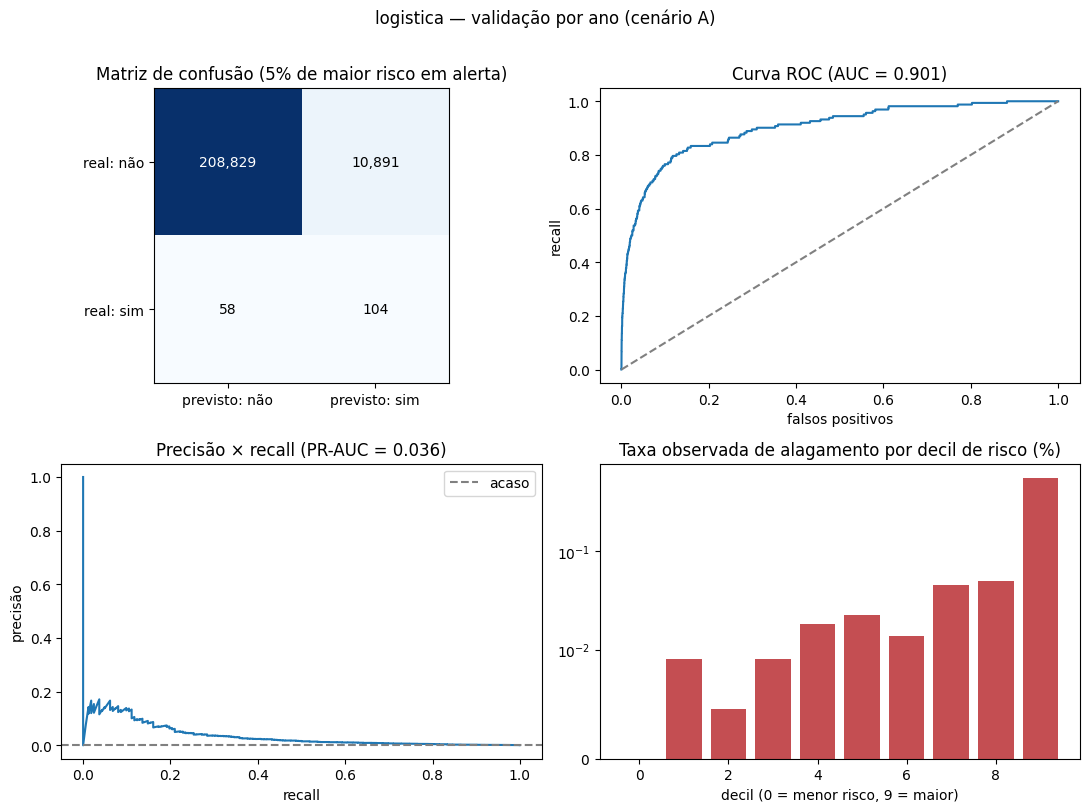

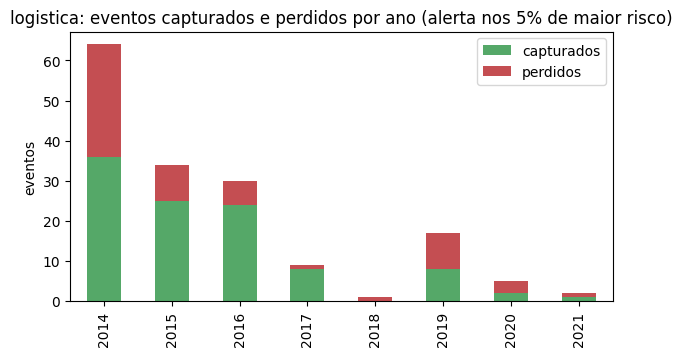

logistica  PR-AUC=0.0360  ROC-AUC=0.9014  recall@top5%=0.642  precisão@top5%=0.0095


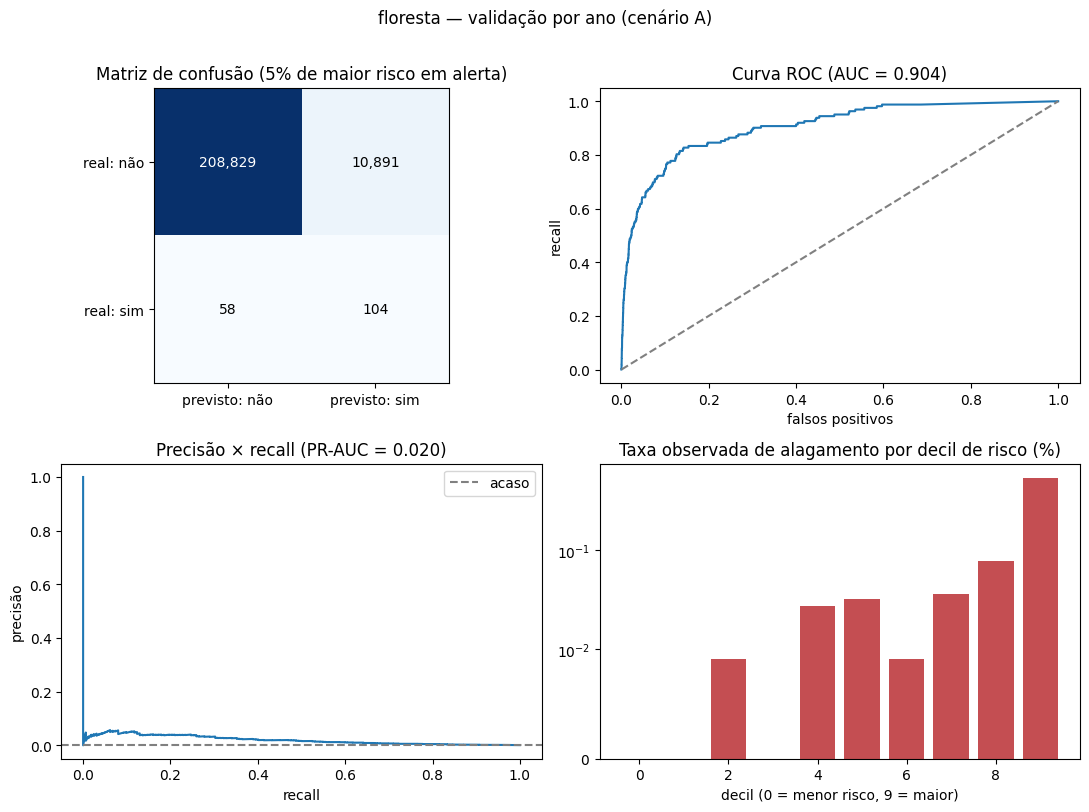

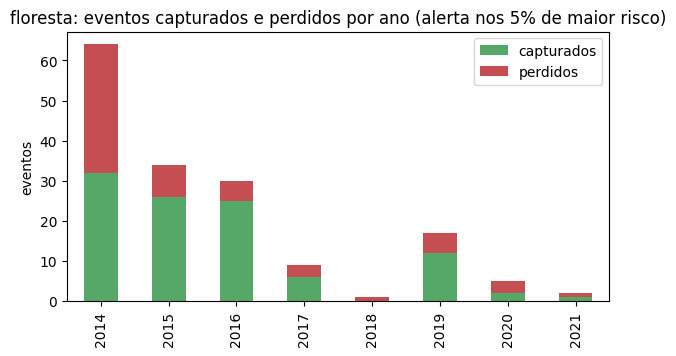

floresta   PR-AUC=0.0203  ROC-AUC=0.9039  recall@top5%=0.642  precisão@top5%=0.0095


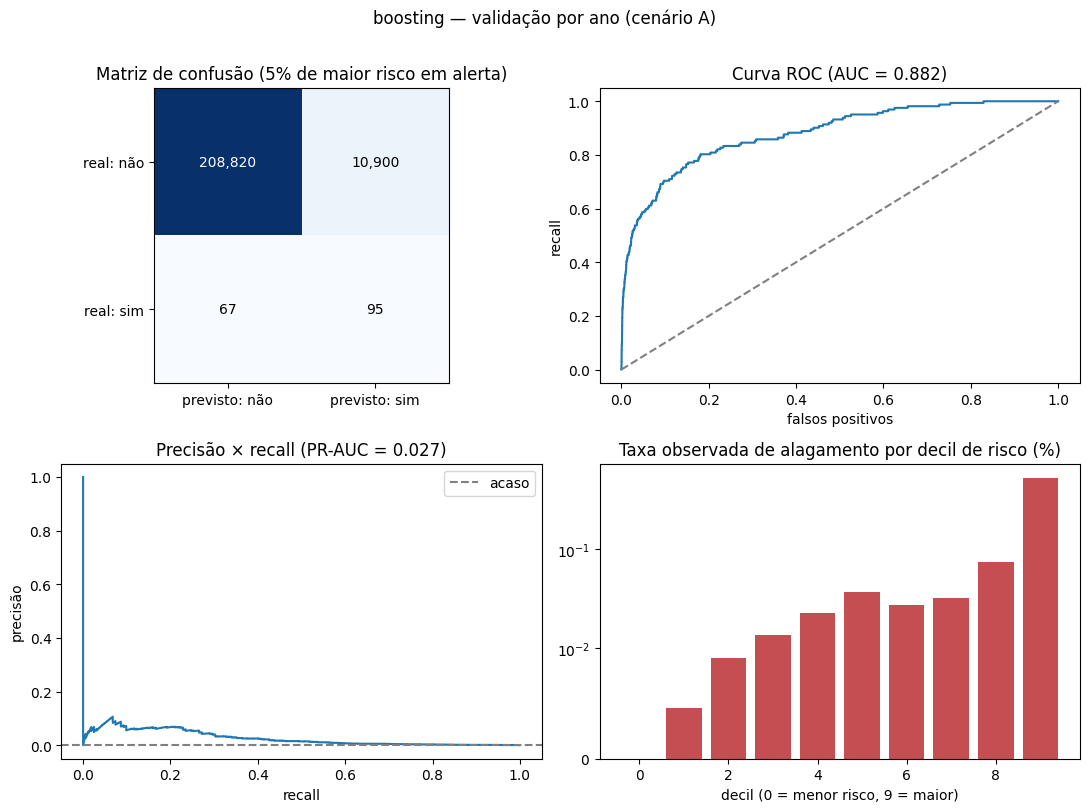

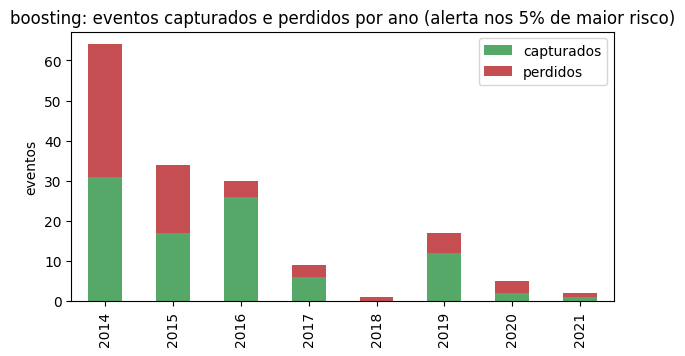

boosting   PR-AUC=0.0269  ROC-AUC=0.8819  recall@top5%=0.586  precisão@top5%=0.0086


In [5]:
resultados, run_ids = {}, {}
for nome in mod.COMPLEXIDADE:
    res = mod.validar_loyo(base, ALVO, FEATURES_A, nome, calcular_treino=True)
    resultados[nome] = res
    oof_ = res["oof"].loc[base.index]
    with mlflow.start_run(run_name=f"{nome}_cenarioA") as r:
        run_ids[nome] = r.info.run_id
        mlflow.set_tags({"etapa": "comparacao_modelos", "cenario": "A", "modelo": nome})
        mlflow.log_params({**{f"hp_{k}": v for k, v in res["params"].items()}, "alvo": ALVO,
                           "validacao": "leave-one-year-out", "n_features": len(FEATURES_A) + 1, "dataset_sha256_16": SHA})
        mlflow.log_metrics(limpa(res["global"]))
        for ano, row in res["por_ano"].iterrows():
            for met in ("pr_auc", "recall_top5"):
                if not np.isnan(row[met]):
                    mlflow.log_metric(f"{met}_por_ano", float(row[met]), step=int(ano))
        t = res["treino"]
        mlflow.log_metrics({"treino_pr_auc_medio": float(t["pr_auc"].mean()), "treino_roc_auc_medio": float(t["roc_auc"].mean()),
                            "treino_recall_top5_medio": float(t["recall_top5"].mean())})
        oof_.to_csv(ART_DIR / f"oof_{nome}.csv.gz")
        mlflow.log_artifact(str(ART_DIR / f"oof_{nome}.csv.gz"), artifact_path="previsoes")
        registrar_fig(painel_modelo(f"{nome} — validação por ano (cenário A)", oof_["y"].values, oof_["p"].values), f"painel_{nome}")
        registrar_fig(figura_erro_por_ano(f"{nome}: eventos capturados e perdidos por ano (alerta nos 5% de maior risco)", oof_), f"erro_por_ano_{nome}")
    g = res["global"]
    print(f"{nome:10s} PR-AUC={g['pr_auc']:.4f}  ROC-AUC={g['roc_auc']:.4f}  recall@top5%={g['recall_top5']:.3f}  precisão@top5%={g['precisao_top5']:.4f}")

## 5. Comparação dos modelos
Tabela, curvas sobrepostas e erro por ano. Em seguida, **intervalos de confiança por reamostragem de dias inteiros** (os eventos se agrupam por tempestade, então reamostrar linhas soltas subestimaria a incerteza) e a **regra de escolha** do protocolo.

,pr_auc,roc_auc,recall_top1,recall_top5,precisao_top5
logistica,0.0360,0.9014,0.3642,0.6420,0.0095
floresta,0.0203,0.9039,0.3519,0.6420,0.0095
boosting,0.0269,0.8819,0.3642,0.5864,0.0086
referencia: so chuva,0.0203,0.8370,0.4259,0.5123,0.0075
referencia: chuva x bairro,0.0441,0.8416,0.4383,0.5926,0.0087


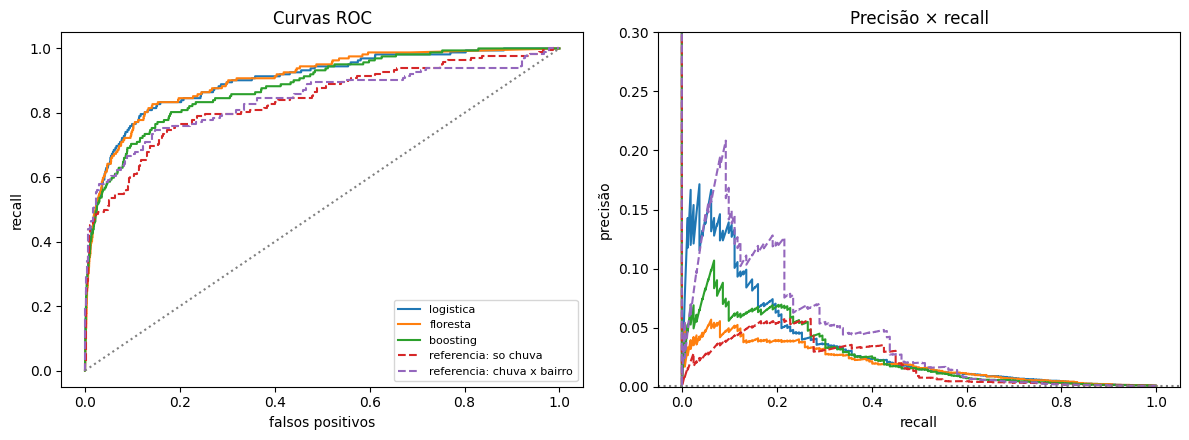

,logistica,floresta,boosting,positivos
ano,,,,
2014,0.500,0.516,0.484,64
2015,0.559,0.618,0.529,34
2016,0.733,0.833,0.867,30
2017,0.889,0.667,0.667,9
2018,0.000,0.000,0.000,1
2019,0.588,0.706,0.706,17
2020,0.400,0.400,0.400,5
2021,0.500,0.500,0.500,2


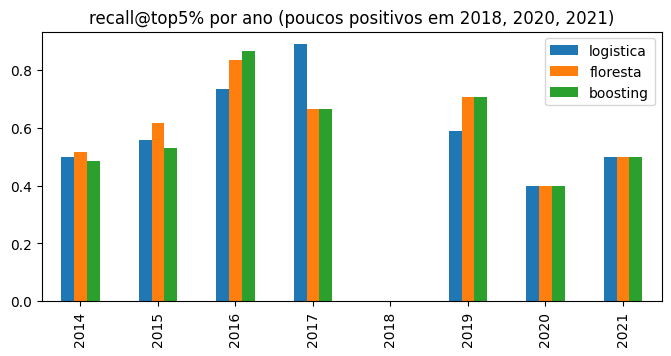

PR-AUC (reamostragem de dias)


,media,IC95 inf,IC95 sup
logistica,0.0405,0.0183,0.0750
floresta,0.0221,0.0110,0.0400
boosting,0.0294,0.0124,0.0582
referencia: so chuva,0.0220,0.0111,0.0344
referencia: chuva x bairro,0.0482,0.0180,0.0894


recall@top5%


,media,IC95 inf,IC95 sup
logistica,0.637,0.541,0.713
floresta,0.637,0.525,0.731
boosting,0.577,0.454,0.674
referencia: so chuva,0.515,0.369,0.653
referencia: chuva x bairro,0.590,0.464,0.697



Melhor PR-AUC média: logistica | modelo escolhido pela regra de parcimônia: logistica
  logistica − floresta: diferença média +0.0184 | logistica ganha em 94% das reamostras
  logistica − boosting: diferença média +0.0111 | logistica ganha em 82% das reamostras


In [6]:
scores = {n: resultados[n]["oof"].loc[base.index, "p"].values for n in mod.COMPLEXIDADE}
todos = {**scores, **refs}
tab = pd.DataFrame({n: mod.metricas(y, s) for n, s in todos.items()}).T
display(tab[["pr_auc", "roc_auc", "recall_top1", "recall_top5", "precisao_top5"]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, s in todos.items():
    estilo = "--" if n.startswith("referencia") else "-"
    fpr, tpr, _ = roc_curve(y, s); ax[0].plot(fpr, tpr, estilo, label=n)
    prec, rec, _ = precision_recall_curve(y, s); ax[1].plot(rec, prec, estilo, label=n)
ax[0].plot([0, 1], [0, 1], ":", color="gray"); ax[0].set_title("Curvas ROC"); ax[0].set_xlabel("falsos positivos"); ax[0].set_ylabel("recall"); ax[0].legend(fontsize=8)
ax[1].axhline(y.mean(), ls=":", color="gray"); ax[1].set_title("Precisão × recall"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisão"); ax[1].set_ylim(0, 0.3)
fig.tight_layout()

with mlflow.start_run(run_name="comparacao_modelos") as r_comp:
    run_comp = r_comp.info.run_id
    mlflow.set_tags({"etapa": "comparacao_modelos", "cenario": "A"})
    registrar_json(PROTOCOLO, "protocolo_de_avaliacao.json")
    registrar_tabela(tab, "comparacao_modelos.csv")
    registrar_fig(fig, "comparacao_curvas")

    rec_ano = pd.DataFrame({n: resultados[n]["por_ano"]["recall_top5"] for n in mod.COMPLEXIDADE})
    rec_ano["positivos"] = resultados[mod.COMPLEXIDADE[0]]["por_ano"]["positivos"]
    display(rec_ano.round(3))
    fig2, ax2 = plt.subplots(figsize=(8, 3.5))
    rec_ano[mod.COMPLEXIDADE].plot(kind="bar", ax=ax2); ax2.set_title("recall@top5% por ano (poucos positivos em 2018, 2020, 2021)"); ax2.set_xlabel("")
    registrar_fig(fig2, "comparacao_recall_por_ano")

    ap_b, rc_b = mod.bootstrap_dias(base["data"].values, y, todos, B=200)
    def resumo(d):
        return pd.DataFrame({n: {"media": v.mean(), "IC95 inf": np.percentile(v, 2.5), "IC95 sup": np.percentile(v, 97.5)} for n, v in d.items()}).T
    print("PR-AUC (reamostragem de dias)"); display(resumo(ap_b).round(4))
    print("recall@top5%"); display(resumo(rc_b).round(3))
    registrar_tabela(resumo(ap_b), "bootstrap_pr_auc.csv"); registrar_tabela(resumo(rc_b), "bootstrap_recall_top5.csv")

    # regra de escolha: do mais simples ao mais complexo, o primeiro que o melhor nao supera de forma clara
    medias = {n: ap_b[n].mean() for n in mod.COMPLEXIDADE}
    melhor = max(medias, key=medias.get)
    escolhido = melhor
    for n in mod.COMPLEXIDADE:
        if n == melhor:
            break
        if (ap_b[melhor] - ap_b[n] > 0).mean() < 0.95:
            escolhido = n
            break
    MODELO_ESCOLHIDO_MANUAL = None            # defina "logistica", "floresta" ou "boosting" para sobrescrever a regra
    if MODELO_ESCOLHIDO_MANUAL:
        escolhido = MODELO_ESCOLHIDO_MANUAL
    mlflow.set_tags({"modelo_melhor_pr_auc": melhor, "modelo_escolhido": escolhido})
    mlflow.log_metrics({f"pr_auc_{n}": float(medias[n]) for n in medias})

print(f"\nMelhor PR-AUC média: {melhor} | modelo escolhido pela regra de parcimônia: {escolhido}")
for n in mod.COMPLEXIDADE:
    if n != melhor:
        d = ap_b[melhor] - ap_b[n]
        print(f"  {melhor} − {n}: diferença média {d.mean():+.4f} | {melhor} ganha em {100*(d > 0).mean():.0f}% das reamostras")

## 6. Análise crítica
O texto abaixo é gerado a partir dos números; complete-o com a interpretação do grupo.

In [7]:
g = {n: resultados[n]["global"] for n in mod.COMPLEXIDADE}
r_chuva, r_cb = tab.loc["referencia: so chuva"], tab.loc["referencia: chuva x bairro"]
linhas_txt = [f"- Maior PR-AUC entre os modelos: **{melhor}** ({medias[melhor]:.4f}); modelo escolhido pela regra de parcimônia: **{escolhido}**.",
              f"- A regressão logística (baseline) obteve PR-AUC {g['logistica']['pr_auc']:.4f} e recall@top5% {g['logistica']['recall_top5']:.1%}; "
              f"a floresta {g['floresta']['pr_auc']:.4f} / {g['floresta']['recall_top5']:.1%}; o boosting {g['boosting']['pr_auc']:.4f} / {g['boosting']['recall_top5']:.1%}.",
              f"- Referências sem ML: 'só chuva' PR-AUC {r_chuva['pr_auc']:.4f} (recall@top5% {r_chuva['recall_top5']:.1%}); "
              f"'chuva × bairro' PR-AUC {r_cb['pr_auc']:.4f} (recall@top5% {r_cb['recall_top5']:.1%}).",
              f"- A taxa base é {y.mean():.4%}: a PR-AUC dos modelos equivale a {max(g[n]['pr_auc'] for n in g)/y.mean():.0f} vezes o acaso, "
              f"mas a precisão@top5% é de apenas {max(g[n]['precisao_top5'] for n in g):.2%}, ou seja, a maioria dos alertas não coincide com um registro de alagamento."]
from IPython.display import Markdown
display(Markdown("\n".join(linhas_txt)))

- Maior PR-AUC entre os modelos: **logistica** (0.0405); modelo escolhido pela regra de parcimônia: **logistica**.
- A regressão logística (baseline) obteve PR-AUC 0.0360 e recall@top5% 64.2%; a floresta 0.0203 / 64.2%; o boosting 0.0269 / 58.6%.
- Referências sem ML: 'só chuva' PR-AUC 0.0203 (recall@top5% 51.2%); 'chuva × bairro' PR-AUC 0.0441 (recall@top5% 59.3%).
- A taxa base é 0.0737%: a PR-AUC dos modelos equivale a 49 vezes o acaso, mas a precisão@top5% é de apenas 0.95%, ou seja, a maioria dos alertas não coincide com um registro de alagamento.

**Pontos para a interpretação do grupo (preencher):**
1. Algum modelo supera claramente as referências sem ML? Os intervalos de confiança permitem afirmar isso ou é empate?
2. O modelo mais complexo compensa o custo em explicabilidade?
3. Quais anos o modelo erra mais e por quê (poucos positivos, mudança de prática de registro, chuva localizada)?
4. A precisão baixa é aceitável para o uso pretendido (priorizar vistorias)? Qual o custo de um alarme falso para a Defesa Civil?

## 7. Validação cruzada, estabilidade e generalização
Quatro análises para responder: *o modelo generaliza ou decorou? Os resultados são estáveis?*

**7.1 Treino × validação** (*overfitting*/*underfitting*). Treino muito melhor que validação indica sobreajuste; ambos baixos indicam subajuste.

In [8]:
gap = []
for n in mod.COMPLEXIDADE:
    t = resultados[n]["treino"]; v = resultados[n]["global"]
    gap.append({"modelo": n, "PR-AUC treino": t["pr_auc"].mean(), "PR-AUC validação": v["pr_auc"],
                "ROC-AUC treino": t["roc_auc"].mean(), "ROC-AUC validação": v["roc_auc"],
                "recall@top5 treino": t["recall_top5"].mean(), "recall@top5 validação": v["recall_top5"]})
gap = pd.DataFrame(gap).set_index("modelo")
gap["gap PR-AUC"] = gap["PR-AUC treino"] - gap["PR-AUC validação"]
display(gap.round(4))

,PR-AUC treino,PR-AUC validação,ROC-AUC treino,ROC-AUC validação,recall@top5 treino,recall@top5 validação,gap PR-AUC
modelo,,,,,,,
logistica,0.0454,0.0360,0.9516,0.9014,0.7537,0.6420,0.0094
floresta,0.2415,0.0203,0.9945,0.9039,1.0000,0.6420,0.2212
boosting,0.4801,0.0269,0.9991,0.8819,1.0000,0.5864,0.4532


**7.2 Estabilidade entre anos.** Média e dispersão do desempenho por ano, considerando só anos com pelo menos 5 eventos (os demais são ruído).

In [9]:
est = []
for n in mod.COMPLEXIDADE:
    pa = resultados[n]["por_ano"]; pa = pa[pa["positivos"] >= 5]
    est.append({"modelo": n, "anos usados": len(pa), "PR-AUC média": pa["pr_auc"].mean(), "PR-AUC desvio": pa["pr_auc"].std(),
                "PR-AUC mín": pa["pr_auc"].min(), "PR-AUC máx": pa["pr_auc"].max(),
                "recall@top5 média": pa["recall_top5"].mean(), "recall@top5 desvio": pa["recall_top5"].std()})
est = pd.DataFrame(est).set_index("modelo")
est["coef. de variação (PR-AUC)"] = est["PR-AUC desvio"] / est["PR-AUC média"]
display(est.round(3))
registrar_tabela(gap.join(est, rsuffix="_est"), "overfitting_estabilidade.csv")

,anos usados,PR-AUC média,PR-AUC desvio,PR-AUC mín,PR-AUC máx,recall@top5 média,recall@top5 desvio,coef. de variação (PR-AUC)
modelo,,,,,,,,
logistica,6,0.044,0.039,0.004,0.112,0.612,0.175,0.892
floresta,6,0.043,0.046,0.002,0.131,0.623,0.151,1.055
boosting,6,0.075,0.073,0.004,0.201,0.609,0.170,0.968


**7.3 Contraste: *k-fold* estratificado × validação por ano.** Mesmas variáveis, mesmo modelo (o escolhido), **sem** a propensão do bairro nos dois lados, para a comparação ser justa. Se o *k-fold* embaralhado parecer muito melhor, a diferença é o **vazamento temporal**: linhas do mesmo dia e do mesmo evento em treino e teste.

In [10]:
m_loyo = mod.validar_loyo(base, ALVO, FEATURES_A, escolhido, usa_propensao=False)["global"]
m_estr, _ = mod.validar_estratificado(base, ALVO, FEATURES_A, escolhido, k=5)
contraste = pd.DataFrame({"validação por ano (honesta)": m_loyo, "k-fold estratificado (otimista)": m_estr}).T
display(contraste[["pr_auc", "roc_auc", "recall_top5", "precisao_top5"]].round(4))
with mlflow.start_run(run_id=run_comp):
    mlflow.log_metrics({"contraste_pr_auc_loyo": float(m_loyo["pr_auc"]), "contraste_pr_auc_kfold_estratificado": float(m_estr["pr_auc"])})
    registrar_tabela(contraste, "contraste_loyo_vs_kfold.csv")

,pr_auc,roc_auc,recall_top5,precisao_top5
validação por ano (honesta),0.0338,0.8998,0.6296,0.0093
k-fold estratificado (otimista),0.0368,0.9207,0.6914,0.0102


**7.4 Curva de aprendizado.** Desempenho em função do número de anos usados no treino (2, 4 ou 7). Se a curva ainda sobe com 7 anos, **mais dados ajudariam** (por exemplo, os anos 2022+ quando houver chuva); se achata cedo, o limite é a informação disponível nas variáveis.

pr_auc         recall_top5        
               mean     std        mean     std
anos_treino                                    
2            0.0120  0.0034      0.4352  0.0131
4            0.0164  0.0067      0.5031  0.0393
7            0.0360  0.0000      0.6420  0.0000

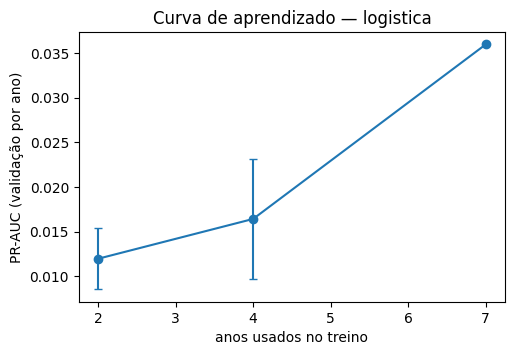

In [11]:
RODAR_CURVA_APRENDIZADO = True            # ~10 min; desligue para economizar tempo
if RODAR_CURVA_APRENDIZADO:
    ca = mod.curva_aprendizado(base, ALVO, FEATURES_A, escolhido, ks=(2, 4, 7), repeticoes=2)
    resumo_ca = ca.groupby("anos_treino")[["pr_auc", "recall_top5"]].agg(["mean", "std"]).round(4)
    display(resumo_ca)
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    m_ = ca.groupby("anos_treino")["pr_auc"].mean(); s_ = ca.groupby("anos_treino")["pr_auc"].std().fillna(0)
    ax.errorbar(m_.index, m_.values, yerr=s_.values, marker="o", capsize=3)
    ax.set_xlabel("anos usados no treino"); ax.set_ylabel("PR-AUC (validação por ano)"); ax.set_title(f"Curva de aprendizado — {escolhido}")
    with mlflow.start_run(run_id=run_comp):
        registrar_fig(fig, "curva_aprendizado")
        registrar_tabela(ca.set_index("anos_treino"), "curva_aprendizado.csv")

## 8. Otimização de hiperparâmetros (Optuna)
**Estratégia.** Otimização bayesiana (TPE) sobre o modelo escolhido, maximizando a **PR-AUC** da validação por ano.

**Cuidado contra otimismo.** Com ~78 dias de evento, é fácil "ajustar os hiperparâmetros ao acaso". Por isso:
1. a busca usa **só os anos 2014–2017** (validação por ano dentro deles);
2. os melhores parâmetros são então avaliados no **teste cronológico 2018–2021**, que a busca nunca viu, e comparados com os parâmetros padrão;
3. só adotamos os parâmetros otimizados se **melhorarem a PR-AUC no teste cronológico**; caso contrário, mantemos os padrão. O teste tem apenas ~25 eventos, então o resultado é um indício, não uma prova.

Para acelerar, a busca treina com 25% dos negativos (o ranking dos positivos não muda); a avaliação final usa os dados completos. Cada tentativa é uma *run* aninhada no MLflow.

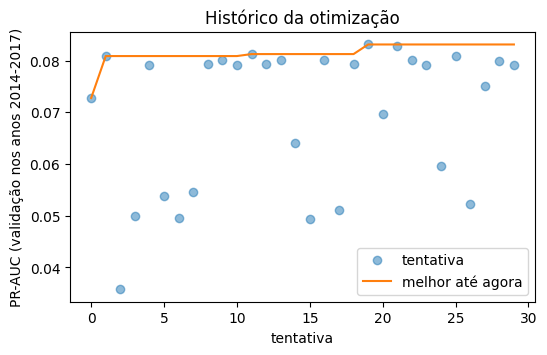

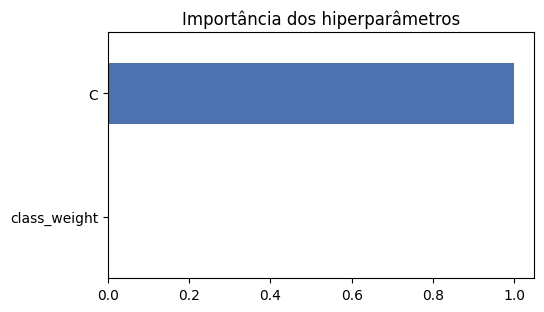

Melhor PR-AUC na busca: 0.0831
Melhores parâmetros: {'C': 0.1656142510824169, 'class_weight': None}


In [12]:
N_TRIALS = 30
FRAC_NEG_TUNING = 0.25
ANOS_TUNING = [2014, 2015, 2016, 2017]
ANOS_TESTE = [2018, 2019, 2020, 2021]

def sugerir(trial, nome):
    if nome == "logistica":
        return {"C": trial.suggest_float("C", 1e-3, 10, log=True),
                "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}
    if nome == "floresta":
        return {"max_depth": trial.suggest_int("max_depth", 3, 14),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 20, 500, log=True),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
                "max_samples": trial.suggest_float("max_samples", 0.05, 0.5)}
    return {"max_depth": trial.suggest_int("max_depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "max_iter": trial.suggest_int("max_iter", 100, 400, step=50),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 50, 600, log=True),
            "l2": trial.suggest_float("l2", 1e-2, 20, log=True),
            "peso_pos_exp": trial.suggest_float("peso_pos_exp", 0.2, 1.0)}

def objetivo(trial):
    params = sugerir(trial, escolhido)
    res = mod.validar_loyo(base, ALVO, FEATURES_A, escolhido, params, anos=ANOS_TUNING, frac_neg_treino=FRAC_NEG_TUNING)
    score = res["global"]["pr_auc"]
    with mlflow.start_run(run_name=f"trial_{trial.number:03d}", nested=True):
        mlflow.log_params({f"hp_{k}": v for k, v in params.items()})
        mlflow.log_metrics({"pr_auc_cv": float(score), "recall_top5_cv": float(res["global"]["recall_top5"])})
    return score

with mlflow.start_run(run_name=f"otimizacao_{escolhido}") as pai:
    id_otim = pai.info.run_id
    mlflow.set_tags({"etapa": "otimizacao", "modelo": escolhido, "ferramenta": "optuna-TPE"})
    mlflow.log_params({"n_trials": N_TRIALS, "frac_negativos_busca": FRAC_NEG_TUNING, "anos_busca": str(ANOS_TUNING),
                       "anos_teste_cronologico": str(ANOS_TESTE), "objetivo": "maximizar pr_auc (validacao por ano)"})
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=mod.SEMENTE))
    study.optimize(objetivo, n_trials=N_TRIALS)
    melhores = dict(study.best_params)
    mlflow.log_metric("melhor_pr_auc_cv", float(study.best_value))
    mlflow.log_params({f"melhor_{k}": v for k, v in melhores.items()})

    trials = study.trials_dataframe()
    registrar_tabela(trials.set_index("number"), "optuna_tentativas.csv")
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(trials["number"], trials["value"], "o", alpha=0.5, label="tentativa"); ax.plot(trials["number"], trials["value"].cummax(), "-", label="melhor até agora")
    ax.set_xlabel("tentativa"); ax.set_ylabel("PR-AUC (validação nos anos 2014-2017)"); ax.set_title("Histórico da otimização"); ax.legend()
    registrar_fig(fig, "optuna_historico")
    try:
        imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
        fig, ax = plt.subplots(figsize=(5.5, 3.2)); imp.plot(kind="barh", ax=ax, color="#4c72b0"); ax.set_title("Importância dos hiperparâmetros")
        registrar_fig(fig, "optuna_importancia")
    except Exception as e:
        print("importância dos hiperparâmetros indisponível:", e)

print("Melhor PR-AUC na busca:", round(study.best_value, 4)); print("Melhores parâmetros:", melhores)

In [13]:
m_pad, _ = mod.treinar_testar(base, ALVO, FEATURES_A, escolhido, None, ANOS_TUNING, ANOS_TESTE)
m_otim, _ = mod.treinar_testar(base, ALVO, FEATURES_A, escolhido, melhores, ANOS_TUNING, ANOS_TESTE)
tab_h = pd.DataFrame({"parâmetros padrão": m_pad, "parâmetros otimizados": m_otim}).T
display(tab_h[["pr_auc", "roc_auc", "recall_top5", "precisao_top5"]].round(4))

ADOTAR = bool(m_otim["pr_auc"] > m_pad["pr_auc"])
PARAMS_FINAIS = melhores if ADOTAR else {}
print("Parâmetros otimizados superam os padrão no teste cronológico?", "SIM — serão adotados" if ADOTAR else "NÃO — mantém os padrão")
with mlflow.start_run(run_id=id_otim):
    mlflow.log_metrics({"teste_cron_pr_auc_padrao": float(m_pad["pr_auc"]), "teste_cron_pr_auc_otimizado": float(m_otim["pr_auc"]),
                        "teste_cron_recall_top5_padrao": float(m_pad["recall_top5"]), "teste_cron_recall_top5_otimizado": float(m_otim["recall_top5"])})
    mlflow.set_tag("parametros_otimizados_adotados", str(ADOTAR))
    registrar_tabela(tab_h, "optuna_teste_cronologico.csv")

,pr_auc,roc_auc,recall_top5,precisao_top5
parâmetros padrão,0.0262,0.8421,0.32,0.0015
parâmetros otimizados,0.0326,0.9205,0.60,0.0028


Parâmetros otimizados superam os padrão no teste cronológico? SIM — serão adotados


**Como ler:** se os parâmetros otimizados não superam os padrão fora da amostra, a busca apenas **se ajustou ao acaso** dos anos 2014–2017 — um resultado legítimo e comum quando há poucos eventos. Nesse caso, mantemos os padrão e documentamos isso.

## 9. Avaliação final, cenário B e modelo final
Com a decisão sobre os hiperparâmetros tomada, repetimos a validação por ano com a configuração final. Também avaliamos o **cenário B** (sem a chuva do dia): ele serve de **modelo reserva** para quando a chuva do dia não estiver disponível (por exemplo, falha do pluviômetro ou da previsão).

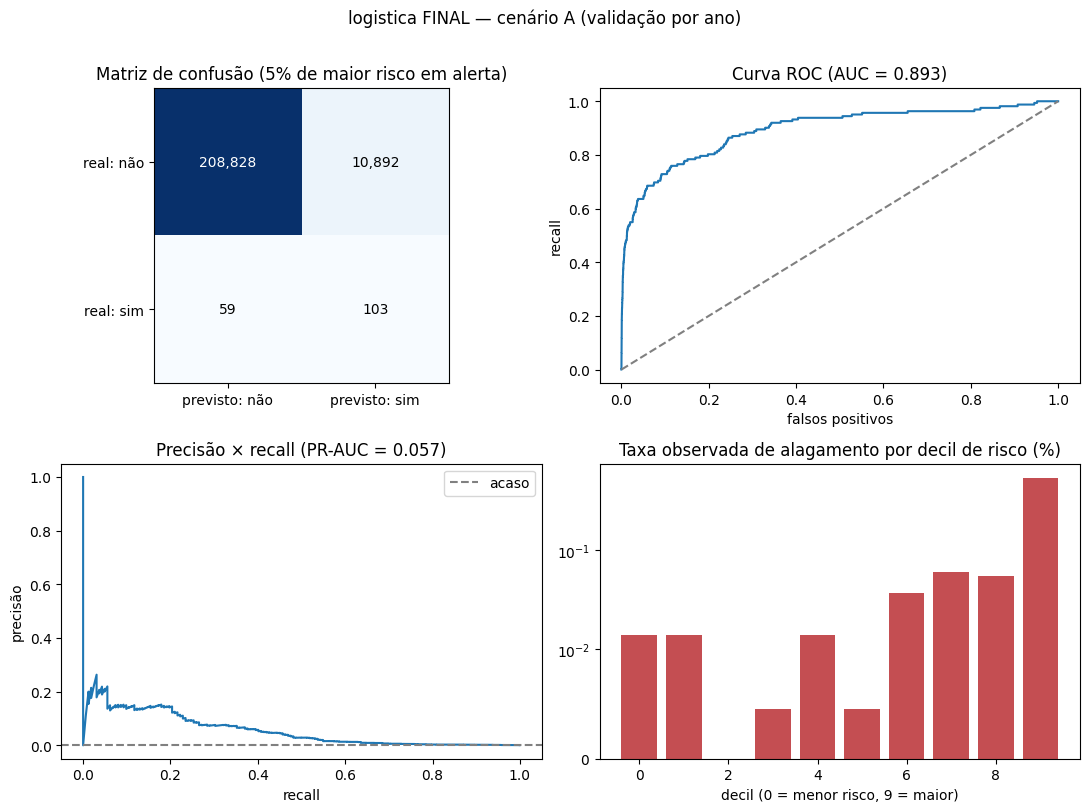

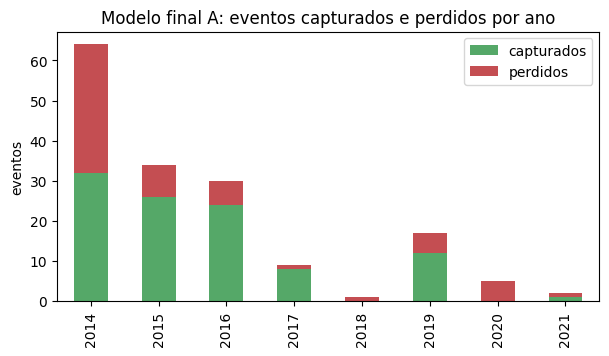

,linhas,eventos,taxa_%,% dos eventos
nivel,,,,
3,1100,64,5.818,39.5
2,3298,24,0.728,14.8
1,10994,23,0.209,14.2
0,204490,51,0.025,31.5


{'pr_auc': 0.057, 'roc_auc': 0.8934, 'taxa_base': 0.0007, 'recall_top1': 0.4753, 'precisao_top1': 0.035, 'recall_top5': 0.6358, 'precisao_top5': 0.0094}


In [14]:
if PARAMS_FINAIS:
    res_A = mod.validar_loyo(base, ALVO, FEATURES_A, escolhido, PARAMS_FINAIS, calcular_treino=True)
else:
    res_A = resultados[escolhido]
oof_A = res_A["oof"].loc[base.index]
p_A = oof_A["p"].values

cortes_A = {"top5": float(np.quantile(p_A, 0.95)), "niveis": [float(np.quantile(p_A, q)) for q in (0.93, 0.98, 0.995)]}
nivel = np.digitize(p_A, cortes_A["niveis"])
niveis = pd.DataFrame({"nivel": nivel, "y": y}).groupby("nivel").agg(linhas=("y", "size"), eventos=("y", "sum"))
niveis["taxa_%"] = (100 * niveis["eventos"] / niveis["linhas"]).round(3)
niveis["% dos eventos"] = (100 * niveis["eventos"] / niveis["eventos"].sum()).round(1)

with mlflow.start_run(run_name=f"final_{escolhido}_cenarioA") as r:
    id_final_A = r.info.run_id
    mlflow.set_tags({"etapa": "avaliacao_final", "cenario": "A", "modelo": escolhido})
    mlflow.log_params({**{f"hp_{k}": v for k, v in res_A["params"].items()}, "hiperparametros_otimizados": str(ADOTAR), "dataset_sha256_16": SHA})
    mlflow.log_metrics(limpa(res_A["global"]))
    registrar_fig(painel_modelo(f"{escolhido} FINAL — cenário A (validação por ano)", oof_A["y"].values, p_A), "painel_final_A")
    registrar_fig(figura_erro_por_ano("Modelo final A: eventos capturados e perdidos por ano", oof_A), "erro_por_ano_final_A")
    registrar_tabela(niveis, "niveis_de_risco_A.csv")
display(niveis.sort_index(ascending=False))
print({k: round(v, 4) for k, v in res_A["global"].items()})

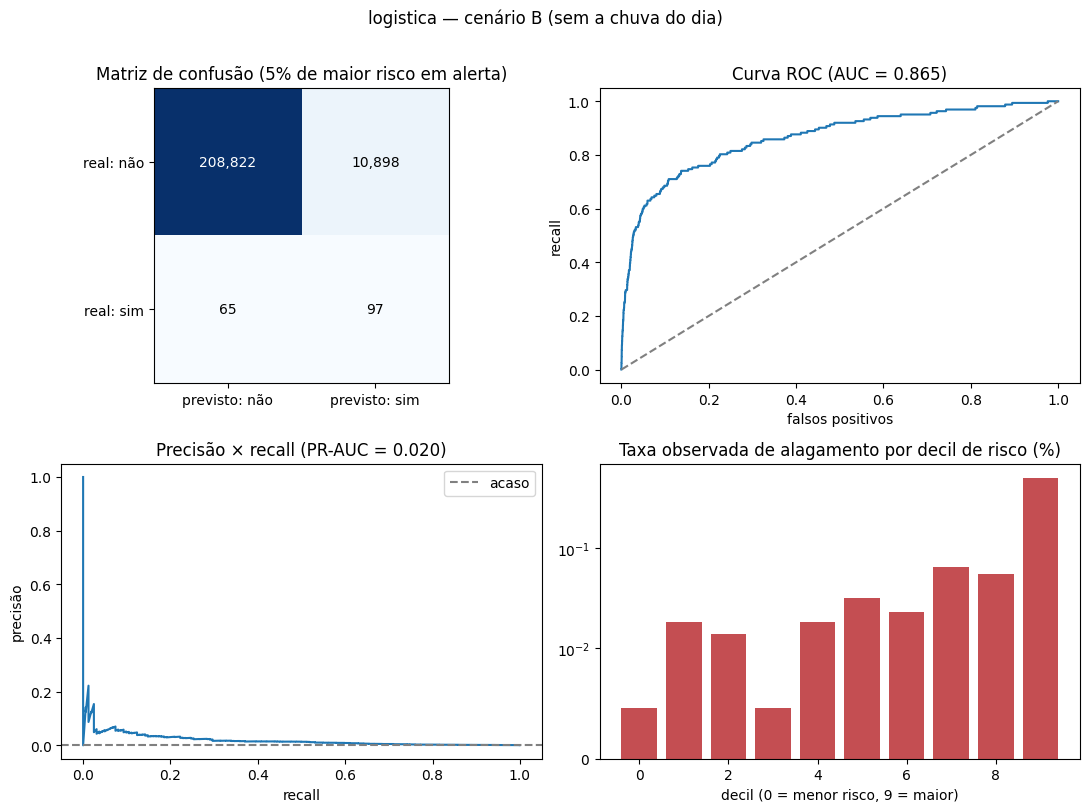

,pr_auc,roc_auc,recall_top5,precisao_top5
A (chuva do dia conhecida),0.0570,0.8934,0.6358,0.0094
B (sem a chuva do dia),0.0202,0.8650,0.5988,0.0088


In [15]:
res_B = mod.validar_loyo(base, ALVO, FEATURES_B, escolhido, PARAMS_FINAIS, calcular_treino=True)
oof_B = res_B["oof"].loc[base.index]; p_B = oof_B["p"].values
cortes_B = {"top5": float(np.quantile(p_B, 0.95)), "niveis": [float(np.quantile(p_B, q)) for q in (0.93, 0.98, 0.995)]}

with mlflow.start_run(run_name=f"final_{escolhido}_cenarioB") as r:
    id_final_B = r.info.run_id
    mlflow.set_tags({"etapa": "avaliacao_final", "cenario": "B", "modelo": escolhido})
    mlflow.log_params({**{f"hp_{k}": v for k, v in res_B["params"].items()}, "n_features": len(FEATURES_B) + 1})
    mlflow.log_metrics(limpa(res_B["global"]))
    registrar_fig(painel_modelo(f"{escolhido} — cenário B (sem a chuva do dia)", oof_B["y"].values, p_B), "painel_final_B")

comp_AB = pd.DataFrame({"A (chuva do dia conhecida)": res_A["global"], "B (sem a chuva do dia)": res_B["global"]}).T
display(comp_AB[["pr_auc", "roc_auc", "recall_top5", "precisao_top5"]].round(4))

### Salvando e registrando os modelos
Treinamos os modelos finais com **todos os anos (2014–2021)** e os registramos no MLflow (*Model Registry*) com os cortes de risco calculados na validação. É este artefato que a API de inferência vai carregar. Verificamos em seguida que o modelo salvo reproduz as previsões do modelo em memória.

In [16]:
def salvar_modelo(cenario, feats, cortes, nome_registro, res, run_id_avaliacao):
    m = mod.ajustar_final(base, ALVO, feats, escolhido, PARAMS_FINAIS)
    m.cortes_ = cortes
    caminho = MODELOS_DIR / f"{nome_registro}.joblib"
    joblib.dump(m, caminho)
    ficha = {"nome": nome_registro, "cenario": cenario, "modelo": escolhido, "hiperparametros": res["params"],
             "alvo": ALVO, "features": feats + ["propensao_bairro"], "entrada_api": feats + ["bairro"],
             "cortes": cortes, "metricas_validacao_por_ano": limpa(res["global"]),
             "dataset_sha256_16": SHA, "anos_treino": sorted(int(a) for a in base["ano"].unique()),
             "avaliacao_run_id": run_id_avaliacao, "gerado_em": datetime.datetime.now().isoformat(timespec="seconds")}
    registrar_json(ficha, f"ficha_{nome_registro}.json")
    mlflow.log_artifact(str(caminho), artifact_path="modelos")
    try:
        info = registrar_modelo(m, f"modelo_{cenario}")
        versao = mlflow.register_model(info.model_uri, nome_registro)
        try:
            _cli.set_registered_model_alias(nome_registro, "campeao", versao.version)
        except Exception:
            pass
        print(f"registrado: {nome_registro} v{versao.version}")
    except Exception as e:
        print(f"AVISO: não foi possível registrar '{nome_registro}' no Model Registry ({type(e).__name__}: {e}). O arquivo {caminho.name} foi salvo.")
    return m, caminho

with mlflow.start_run(run_name="modelo_final") as r:
    id_modelo_final = r.info.run_id
    mlflow.set_tags({"etapa": "modelo_final", "modelo": escolhido})
    modelo_A, caminho_A = salvar_modelo("A", FEATURES_A, cortes_A, "risco_alagamento", res_A, id_final_A)
    modelo_B, caminho_B = salvar_modelo("B", FEATURES_B, cortes_B, "risco_alagamento_cenario_B", res_B, id_final_B)

# verificacao: o modelo salvo reproduz as previsoes do modelo em memoria
amostra = base.sample(5000, random_state=mod.SEMENTE)
recarregado = joblib.load(caminho_A)
print("modelo salvo reproduz as previsões:", bool(np.allclose(modelo_A.prever(amostra), recarregado.prever(amostra))))
print("níveis de risco previstos (0-3) na amostra:", np.bincount(recarregado.nivel(amostra), minlength=4))

2026/10/26 21:59:20 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/10/26 21:59:27 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/10/26 21:59:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 21:59:27 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
Successfully registered model 'risco_alagamento'.
Created version '1' of model 'risco_alagamento'.


registrado: risco_alagamento v1


2026/10/26 21:59:29 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/10/26 21:59:34 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


registrado: risco_alagamento_cenario_B v1
modelo salvo reproduz as previsões: True
níveis de risco previstos (0-3) na amostra: [4602  288   76   34]


Successfully registered model 'risco_alagamento_cenario_B'.
Created version '1' of model 'risco_alagamento_cenario_B'.


## 10. Resumo, limitações e próximos passos

**O que este notebook entrega**
- Protocolo de avaliação definido antes dos experimentos.
- Baseline (regressão logística) e mais dois modelos, comparados com métricas apropriadas a evento raro, matriz de confusão, curvas ROC/PR, erro por ano e intervalos de confiança.
- Otimização de hiperparâmetros com Optuna, avaliada fora da amostra.
- Análise de estabilidade, overfitting e generalização, incluindo o contraste com o *k-fold* estratificado e a curva de aprendizado.
- Modelos finais (cenários A e B) salvos em `modelos/` e registrados no MLflow, com cortes de nível de risco.

**Limitações que devem acompanhar qualquer apresentação**
- Só 162 eventos, concentrados em 78 dias: as métricas têm incerteza grande e as diferenças pequenas entre modelos são empate.
- O rótulo é um registro da Defesa Civil, não alagamento medido; a "propensão do bairro" mistura vulnerabilidade real com viés de registro.
- Uma só estação de chuva (INMET A301), com dados até 2021. A chuva do dia é observada, não prevista.
- A precisão nos 5% de maior risco é baixa: a maioria dos alertas não coincide com um registro. O modelo serve para **priorizar**, não para decidir sozinho.

**Próximos passos**
1. **Integração (item 7 do documento):** a API carrega `modelos/risco_alagamento.joblib` (ou o modelo registrado no MLflow) e chama `modelo.prever(df)` com as colunas de `entrada_api` da ficha. O pluviômetro e o simulador só entram nessa etapa, fornecendo a chuva do dia por MQTT.
2. **Airflow:** transformar os notebooks 01 e 02 em tarefas (`preparacao`, `treino`, `avaliacao`, `registro`).
3. **Dados novos:** chuva de 2022+ (APAC/CEMADEN) para um teste de verdade, e a altitude relativa à drenagem (HAND).